# ADP 모의고사 1회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: 모의고사 1.ipynb

원 자료 조건: 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'모의고사/1회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')

# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 추첨 기록의 동시 출현

분석가는 합성 추첨 400회에서 번호가 함께 나타나는 패턴을 요약하려 한다. 순서는 의미가 없고 후보 번호는 1~12로 제한되어 있다. 이 기록으로 다음 실제 로또 번호의 당첨 확률을 주장할 수 없다.

자료: lotto.csv

### 1-1

한 추첨을 하나의 거래로 표현하고 순서·중복을 처리하시오. 번호 출현 상위 10개를 시각화하고 빈도의 의미와 한계를 설명하시오.

**판단 및 풀이 근거**

각 회차를 집합으로 바꿔 추첨 순서와 중복을 배제합니다. 많이 나온 번호가 다음 추첨에서 더 유리하다는 뜻은 아닙니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

3     232
8     204
6     203
5     200
4     198
7     198
1     197
11    196
9     196
2     193
dtype: int64


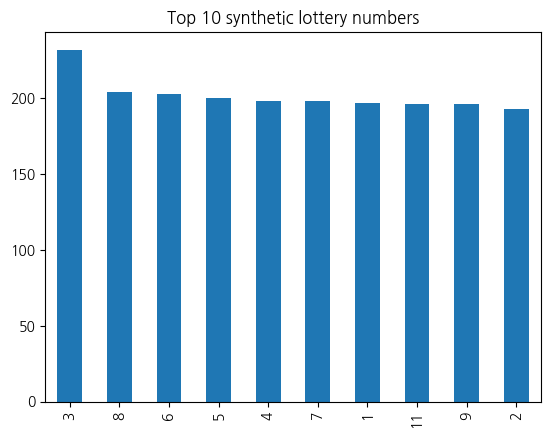

In [2]:
set_question('1-1')
lotto=load('lotto.csv'); transactions=[set(map(str,row)) for row in lotto.to_numpy()]
assert all(len(t)==6 for t in transactions)
from collections import Counter
counts=Counter(x for t in transactions for x in t)
top=pd.Series(counts).sort_values(ascending=False).head(10)
print(top);top.plot.bar();plt.title('Top 10 synthetic lottery numbers');plt.show()

### 1-2

동시 출현 규칙을 생성할 방안을 선택하시오. 최소 지지도 .002·최소 신뢰도 .8·합계 항목 수 2~6을 적용하고 lift 상위 30개를 rules_1 및 CSV로 저장하시오. 규칙의 해석과 예측력 검증의 차이를 설명하시오.

**판단 및 풀이 근거**

조건을 정확히 유지합니다. antecedent/consequent가 모두 비어 있지 않으므로 최소 합계 길이는 2입니다. 향상도가 커도 인과·예측력이 검증된 것은 아닙니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [3]:
set_question('1-2')
from src.Association.apriori import run_apriori
association=run_apriori([list(t) for t in transactions],overrides={'min_support':.002,'min_confidence':.8,'min_lift':0.,'max_length':6,'max_rules':300000,'max_candidates':300000})
rules_1=association.rules.sort_values('lift',ascending=False).head(30)
print(rules_1);rules_1.to_csv(OUT/'rules_1.csv',index=False)
print('전체 규칙 수:',len(association.rules))

           antecedents consequents  support  ...      lift  leverage  conviction
15    (1, 12, 2, 3, 5)       (10,)   0.0025  ...  2.094241  0.001306         inf
84    (12, 2, 5, 8, 9)       (10,)   0.0025  ...  2.094241  0.001306         inf
20    (1, 12, 2, 8, 9)       (10,)   0.0025  ...  2.094241  0.001306         inf
75    (11, 3, 5, 7, 9)       (10,)   0.0025  ...  2.094241  0.001306         inf
97     (2, 5, 6, 8, 9)       (10,)   0.0025  ...  2.094241  0.001306         inf
79    (11, 4, 5, 8, 9)       (10,)   0.0025  ...  2.094241  0.001306         inf
85    (12, 2, 6, 8, 9)       (10,)   0.0025  ...  2.094241  0.001306         inf
122    (2, 3, 4, 6, 7)       (12,)   0.0025  ...  2.083333  0.001300         inf
21    (1, 10, 3, 4, 7)       (12,)   0.0025  ...  2.083333  0.001300         inf
87    (10, 2, 7, 8, 9)       (12,)   0.0025  ...  2.083333  0.001300         inf
68   (10, 11, 2, 8, 9)       (12,)   0.0025  ...  2.083333  0.001300         inf
80    (10, 2, 3, 4, 5)      

## 2. 선수 시장가치 설명

구단은 선수의 신체 특성·포지션·주발과 시장가치 Value의 관계를 알고자 한다. 독립 선수 표본이며 집단 평균 비교의 연습에는 정규 오차·등분산을 작업 가정으로 두고 실제 적합성의 한계를 검토한다. 이 대문항 전체는 같은 FIFA 자료를 사용한다.

자료: FIFA.csv

### 2-1

키가 피트·인치 문자열로 기록되어 있다. 문항상 1피트=30cm, 1인치=2.5cm로 Height_cm을 만들고 실제 단위 환산과의 차이를 설명하시오.

**판단 및 풀이 근거**

공식 단위 환산값보다 문제의 지시값을 따릅니다. 동일 자료로 실제 환산을 적용하면 값이 달라집니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [4]:
set_question('2-1')
fifa=load('FIFA.csv');parts=fifa.Height.str.extract(r"(\d+)'(\d+)").astype(float)
fifa['Height_cm']=parts[0]*30+parts[1]*2.5
print(fifa[['Height','Height_cm']].head())

  Height  Height_cm
0    5'2      155.0
1    6'2      185.0
2   6'11      207.5
3    6'2      185.0
4    5'7      167.5


### 2-2

포지션을 Forward(ST/LW)·Midfielder(CM/CDM)·Defender(CB/LB/RB)·GoalKeeper(GK)로 통합하고 Position_Class 범주형 변수를 구성하시오. 미매핑 값을 검증하시오.

**판단 및 풀이 근거**

Pandas category로 factor에 대응합니다. 매핑 표는 첨부 코드에서 복원한 범주 규칙입니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [5]:
set_question('2-2')
positions={'ST':'Forward','LW':'Forward','CM':'Midfielder','CDM':'Midfielder','CB':'Defender','LB':'Defender','RB':'Defender','GK':'GoalKeeper'}
fifa['Position_Class']=pd.Categorical(fifa.Position.map(positions))
assert not fifa.Position_Class.isna().any()
print(fifa.Position_Class.value_counts())

Position_Class
Defender      131
Midfielder     81
Forward        77
GoalKeeper     31
Name: count, dtype: int64


### 2-3

포지션 네 집단의 평균 시장가치가 같은지 유의수준 5%에서 판단하시오. 검정 선정 근거·가정·가설·통계량·p-value·기각 여부를 제시하고, 필요하면 차이가 있는 집단을 후속 비교하시오.

**판단 및 풀이 근거**

독립 집단의 수치 반응을 설명하는 요인 모형을 선택한다. 한 요인이면 H0: 모든 집단 평균이 같다, H1: 적어도 하나 다르다. 두 요인이면 주효과와 상호작용의 가설·p값을 각각 구분한다. 정규 오차·등분산은 작업 가정이며 적합성을 검토한다.

**계산·해석 상세**

H0: 네 포지션의 평균 시장가치가 같습니다. 가정을 확인하고 유의할 때 Tukey HSD로 다중 비교합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [6]:
set_question('2-3')
anova(fifa,'Value','Position_Class')

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_aov_model=anova(fifa,'Value','Position_Class')
report_anova(_aov_model,'Value',['Position_Class'])

                         sum_sq     df         F    PR(>F)
C(Position_Class)  5.394107e+07    3.0  8.835609  0.000012
Residual           6.430562e+08  316.0       NaN       NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
등분산 Levene: LeveneResult(statistic=np.float64(1.1645781347621291), pvalue=np.float64(0.3233591329049553))
        Multiple Comparison of Means - Tukey HSD, FWER=0.05        
  group1     group2    meandiff  p-adj    lower      upper   reject
-------------------------------------------------------------------
  Defender    Forward    37.4301 0.9978  -491.6415  566.5018  False
  Defender GoalKeeper -1385.1795    0.0 -2121.0559 -649.3031   True
  Defender Midfielder   -34.8066 0.9982  -555.5858  485.9725  False
   Forward GoalKeeper -1422.6096    0.0  -2206.309 -638.9102   True
   Forward Midfielder   -72.2368 0.9888   -658.651  514.1775  False
GoalKeeper Midfielder  1350.3728 0.0001   572.2476 2128.4981   True
-------------------------------------------------------------

### 2-4

주발에 따른 평균 시장가치의 차이가 포지션별로 달라지는지 조사하시오. 두 요인의 효과와 상호작용을 평가할 방법을 선택하고 각 효과의 가설·통계량·p-value·기각 여부를 구분해 해석하시오.

**판단 및 풀이 근거**

독립 집단의 수치 반응을 설명하는 요인 모형을 선택한다. 한 요인이면 H0: 모든 집단 평균이 같다, H1: 적어도 하나 다르다. 두 요인이면 주효과와 상호작용의 가설·p값을 각각 구분한다. 정규 오차·등분산은 작업 가정이며 적합성을 검토한다.

**계산·해석 상세**

주발·포지션의 주효과와 교호작용을 분리합니다. 교호작용이 크면 주효과만으로 평균을 해석하기 어렵습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [7]:
set_question('2-4')
anova(fifa,'Value','Position_Class','Preferred_Foot')

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_aov_model=anova(fifa,'Value','Position_Class','Preferred_Foot')
report_anova(_aov_model,'Value',['Position_Class', 'Preferred_Foot'])

                                           sum_sq     df         F    PR(>F)
C(Position_Class)                    5.179904e+07    3.0  8.765879  0.000013
C(Preferred_Foot)                    3.148238e+06    1.0  1.598316  0.207086
C(Position_Class):C(Preferred_Foot)  2.535464e+07    3.0  4.290731  0.005499
Residual                             6.145533e+08  312.0       NaN       NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
합성 자료의 예시 추론. 정규성·등분산·독립성 및 표본 설계를 실제 자료에서 재검증하세요.
                                           sum_sq     df         F    PR(>F)
C(Position_Class)                    5.179904e+07    3.0  8.765879  0.000013
C(Preferred_Foot)                    3.148238e+06    1.0  1.598316  0.207086
C(Position_Class):C(Preferred_Foot)  2.535464e+07    3.0  4.290731  0.005499
Residual                             6.145533e+08  312.0       NaN       NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
합성 자료의 예시 추론. 정규성·등분산·독립성 및 표본 설계를 실제 자료에서 재검증하세요.
{
  "question": "2-4",
  "method": "독립 집

### 2-5

Age·Overall·Wage·Height_cm·Weight_lb로 시장가치를 설명할 모형을 구성하시오. 추가와 제거를 허용하는 변수 선택 기준·과정·계수를 제시하고 선택 후 추론과 인과 해석의 한계를 설명하시오.

**판단 및 풀이 근거**

단계적 선택 기준을 AIC로 명시합니다. 첨부 답안의 임의 열 제거 대신 엄격한 AIC 개선을 반복합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [8]:
set_question('2-5')
fifa_ols=select_ols(fifa,'Value',['Age','Overall','Wage','Height_cm','Weight_lb'],'stepwise')

선택 변수: ['Wage', 'Overall']
   step      features          AIC
0     1          Wage  5083.797969
1     2  Wage,Overall  5008.395895
                            OLS Regression Results                            
Dep. Variable:                  Value   R-squared:                       0.835
Model:                            OLS   Adj. R-squared:                  0.834
Method:                 Least Squares   F-statistic:                     799.8
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          1.38e-124
Time:                        09:51:46   Log-Likelihood:                -2501.2
No. Observations:                 320   AIC:                             5008.
Df Residuals:                     317   BIC:                             5020.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]

## 3. 영화 리뷰 요약

별도의 합성 영화 리뷰와 품사 사전으로 관심 주제를 요약하려 한다. 사전은 Noun/Adjective를 명시하며 실제 원문 형태소 분석기의 대체 성능을 주장하지 않는다.

자료: reviews.csv + lexicon.csv

### 3-1

문서 경계를 유지하며 숫자·특수문자를 정제하고 정제 결과를 저장하시오. 분석 대상 문서와 어휘 사전의 역할을 구분하시오.

**판단 및 풀이 근거**

숫자·특수 문자를 제거하고 각 문서를 보존합니다. 원문 “리뷰 파일을 사전에 등록”은 모호하므로 어휘 사전과 문서를 구분합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [9]:
set_question('3-1')
reviews=load('reviews.csv');lexicon=load('lexicon.csv');reviews['clean']=reviews.text.map(clean_text)
print(reviews[['text','clean']].head());reviews.to_csv(OUT/'clean_reviews.csv',index=False)

                           text                  clean
0   학교 맛 호텔 배송 영화 여행 빠르다 123 !@   학교 맛 호텔 배송 영화 여행 빠르다
1    맛 배송 기생충 맛 여행 학교 좋다 123 !@    맛 배송 기생충 맛 여행 학교 좋다
2  공구 학교 학교 호텔 행복 학교 즐겁다 123 !@  공구 학교 학교 호텔 행복 학교 즐겁다
3  영화 공구 기생충 호텔 여행 가족 좋다 123 !@  영화 공구 기생충 호텔 여행 가족 좋다
4   호텔 호텔 영화 맛 행복 기생충 좋다 123 !@   호텔 호텔 영화 맛 행복 기생충 좋다


### 3-2

주어진 사전의 명사를 열로 하는 문서별 단어 빈도 표현을 구축·저장하고 상위 10개 명사 빈도를 시각화하시오. 원 빈도와 가중 표현의 차이를 설명하시오.

**판단 및 풀이 근거**

TDM은 문서별 행·사전 단어별 열의 원 빈도입니다. 희소 표현은 실제 대규모 텍스트에서 유지하는 것이 좋습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

   영화  가족  여행  호텔  공구  배송  맛  학교  행복  기생충
0   1   0   1   1   0   1  1   1   0    0
1   0   0   1   0   0   1  2   1   0    1
2   0   0   0   1   1   0  0   3   1    0
3   1   1   1   1   1   0  0   0   0    1
4   1   0   0   2   0   0  1   0   1    1
  word  count
0   호텔     44
1   학교     41
2   영화     40
3   배송     36
4   공구     35
5   행복     35
6    맛     34
7   여행     32
8   가족     32
9  기생충     31


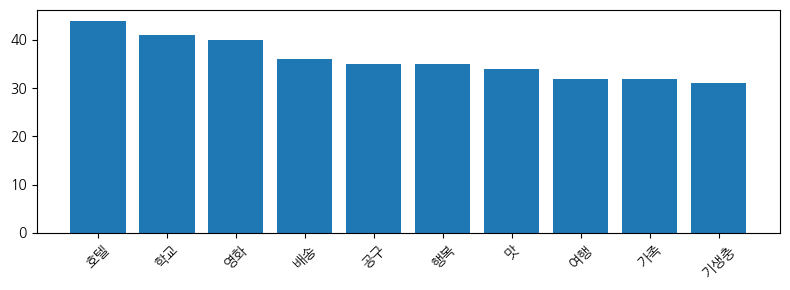

In [10]:
set_question('3-2')
from sklearn.feature_extraction.text import CountVectorizer
vocab=lexicon.loc[lexicon.pos=='Noun','word'].tolist()
vectorizer=CountVectorizer(vocabulary=vocab,token_pattern=r'(?u)\b\w+\b')
tdm=pd.DataFrame(vectorizer.fit_transform(reviews.clean).toarray(),columns=vocab)
print(tdm.head());tdm.to_csv(OUT/'TDM.csv',index=False)
word_plot(lexical_pos(reviews.text,lexicon),10)